<a href="https://colab.research.google.com/github/0110225150-hub/ti05_salma_0110225150/blob/main/MLmandiri5_Salma.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Membaca dataset Iris
df = pd.read_csv('/content/drive/MyDrive/ML 2026/Praktikum05/data/dataset_iris.csv')

# Menampilkan 5 data teratas
df.head()

# Menampilkan informasi ringkas mengenai dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


In [ ]:
print("Jumlah Missing Value:")
print(df.isnull().sum())

print("\nJumlah Data Duplikat:", df.duplicated().sum())
df = df.drop_duplicates()

if 'Id' in df.columns:
    df = df.drop(columns=['Id'])

df.info()

Jumlah Missing Value:
Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

Jumlah Data Duplikat: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   SepalLengthCm  150 non-null    float64
 1   SepalWidthCm   150 non-null    float64
 2   PetalLengthCm  150 non-null    float64
 3   PetalWidthCm   150 non-null    float64
 4   Species        150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


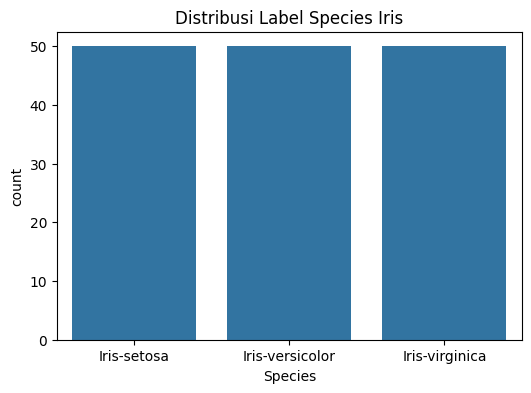

In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(x='Species', data=df)
plt.title('Distribusi Label Species Iris')
plt.show()

In [ ]:
# Mapping label target -> kode untuk target
species_cat = df['Species'].astype('category')
species_classes = list(species_cat.cat.categories) # menyimpan nama kelas asli ['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
df['Species'] = species_cat.cat.codes

df.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


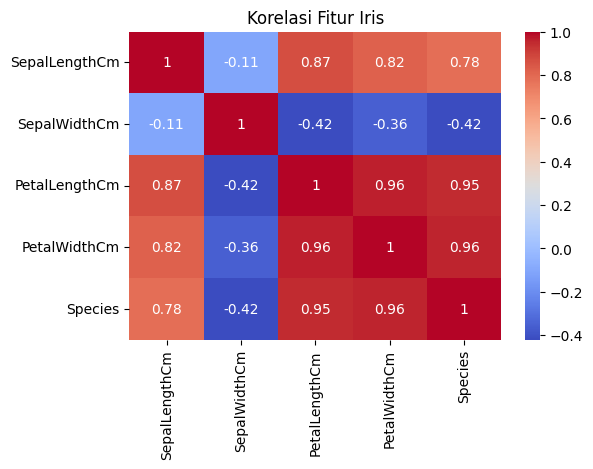

In [ ]:
plt.figure(figsize=(6, 4))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title('Korelasi Fitur Iris')
plt.show()

In [ ]:
# Memilih fitur (X) dan target (y)
feature_cols = ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']
X = df[feature_cols]
y = df['Species']

# Membagi dataset (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah Data Training:", len(X_train))
print("Jumlah Data Testing :", len(X_test))

Jumlah Data Training: 120
Jumlah Data Testing : 30


In [ ]:
# Membangun model Decision Tree
dt = DecisionTreeClassifier(
    criterion='gini',
    max_depth=3, # membatasi kedalaman pohon agar tidak overfitting
    random_state=42
)

# Melatih model menggunakan data training
dt.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=3, random_state=42)

In [ ]:
# Prediksi data testing
y_pred = dt.predict(X_test)

# Evaluasi Performa Model
print("Akurasi:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(
    y_test, y_pred, target_names=species_classes
))

Akurasi: 96.67 %

Confusion Matrix:
 [[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]

Classification Report:
                  precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30



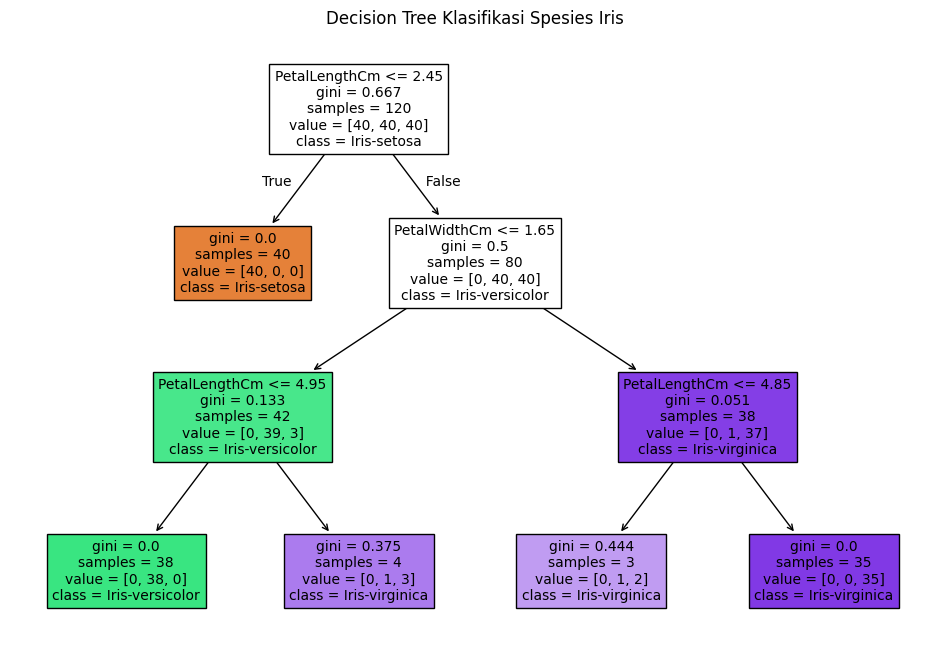

In [ ]:
plt.figure(figsize=(12, 8))
plot_tree(
    dt,
    feature_names=feature_cols,
    class_names=species_classes,
    filled=True,
    fontsize=10
)
plt.title("Decision Tree Klasifikasi Spesies Iris")
plt.show()

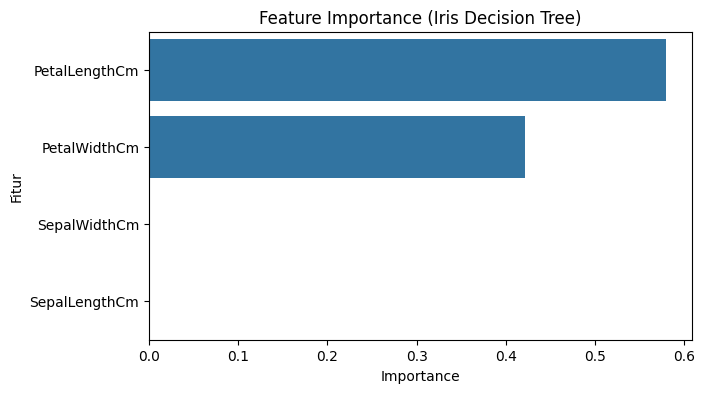

PetalLengthCm    0.579077
PetalWidthCm     0.420923
SepalWidthCm     0.000000
SepalLengthCm    0.000000
dtype: float64


In [ ]:
imp = pd.Series(dt.feature_importances_, index=feature_cols).sort_values(ascending=False)

plt.figure(figsize=(7, 4))
sns.barplot(x=imp, y=imp.index)
plt.title("Feature Importance (Iris Decision Tree)")
plt.xlabel("Importance")
plt.ylabel("Fitur")
plt.show()

print(imp)

In [ ]:
scores = {}
for d in range(1, 10):
    m = DecisionTreeClassifier(max_depth=d, random_state=42)
    m.fit(X_train, y_train)
    scores[d] = accuracy_score(y_test, m.predict(X_test))

best_d = max(scores, key=scores.get)
print("Best max_depth:", best_d, "| Acc:", round(scores[best_d] * 100, 2), "%")

Best max_depth: 3 | Acc: 96.67 %
